# COU 07506 Digital Signal Processing — Week 02: Lab 1A — Sampling, Aliasing and Quantization

- **Name:** Faida Sylvester Mosses
- **Registration No.:** 240647474625
- **Class:** BEng24ETE (Stream 2)
- **Group:** 09
- **Date:** 25 November 2026
- **Instructor checkpoints signed:** [ ] 1  [ ] 2

### Setup — standard imports (Lab 1A)
Load the libraries used in every lab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

### Pre-lab (Lab 1A)
**(a)** A 7 kHz tone is sampled at 10 kHz. What frequency appears?

**(b)** Compute Δ and the theoretical SQNR for an 8-bit quantizer with a ±1 V range.

In [2]:
# (a) alias of a 7 kHz tone sampled at 10 kHz
F, fs_a = 7000, 10000
m = round(F / fs_a)
F_alias = abs(F - m * fs_a)
print(f"(a) m = {m}, alias frequency = {F_alias} Hz")

# (b) quantization step and theoretical SQNR for 8 bits, range +/-1 V
B, Xm = 8, 1.0
delta = 2 * Xm / 2**B
sqnr = 6.02 * B + 1.76
print(f"(b) step = {delta} V = {delta*1000:.2f} mV, SQNR = {sqnr:.2f} dB")

(a) m = 1, alias frequency = 3000 Hz
(b) step = 0.0078125 V = 7.81 mV, SQNR = 49.92 dB


**Pre-lab answers.**

**(a)** The sampling rate is 10 kHz, so the highest frequency that can be represented is fs/2 = 5 kHz. The 7 kHz tone is above this limit, so it aliases. F_alias = |F − m·fs| = |7000 − 1 × 10000| = 3000 Hz. The tone appears at **3 kHz**.

**(b)** For B = 8 bits and a range of ±1 V, the step is Δ = 2·Xm / 2^B = 2 / 256 = 0.0078125 V ≈ **7.81 mV**. The theoretical SQNR for a full-scale sinusoid is 6.02·B + 1.76 = 6.02 × 8 + 1.76 ≈ **49.92 dB**.

### Task 2.1 — Aliasing of a sinusoid (Lab 1A)
Part 1: a 7 Hz tone sampled at fs = 10 Hz.

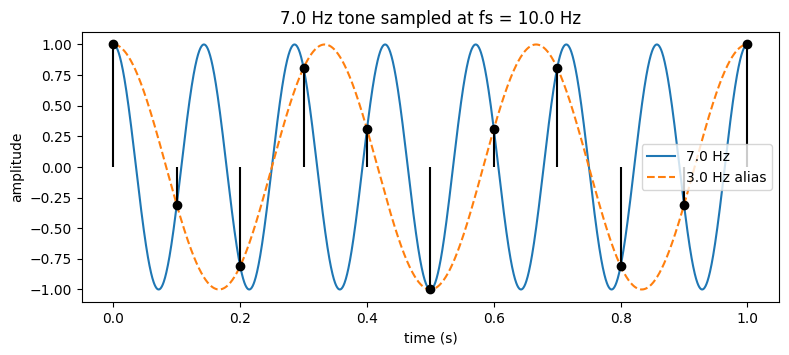

In [3]:
f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs*round(f0/fs))

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
plt.title(f"{f0} Hz tone sampled at fs = {fs} Hz")
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.legend()
plt.show()

#### Task 2.1 — Part 2: repeat for fs = 10, 12, 14 and 20 Hz (Lab 1A)
Find the alias frequency in each case and compare it with |F − k·fs|.

fs =   10 Hz | k = 1 | alias = 3 Hz | same samples: True
fs =   12 Hz | k = 1 | alias = 5 Hz | same samples: True
fs =   14 Hz | k = 0 | alias = 7 Hz | same samples: True
fs =   20 Hz | k = 0 | alias = 7 Hz | same samples: True


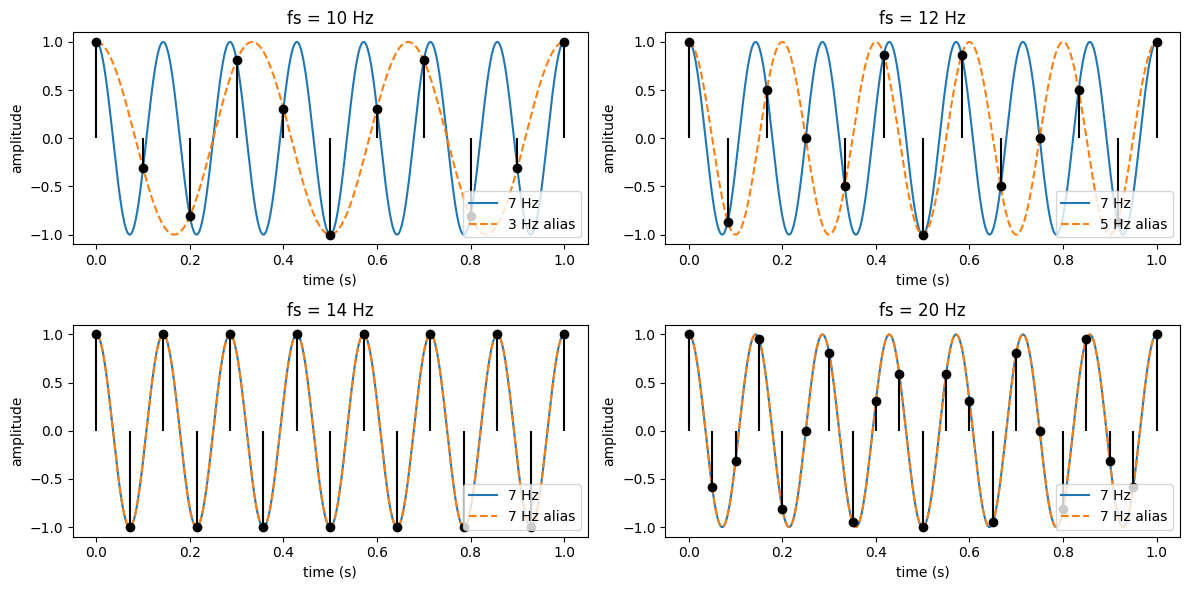

In [4]:
f0 = 7.0
t = np.linspace(0, 1, 2000)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, fs in zip(axes.flat, [10.0, 12.0, 14.0, 20.0]):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    k = round(f0 / fs)
    f_alias = abs(f0 - fs*k)
    same = np.allclose(np.cos(2*np.pi*f0*tn), np.cos(2*np.pi*f_alias*tn))
    print(f"fs = {fs:4.0f} Hz | k = {k} | alias = {f_alias:.0f} Hz | same samples: {same}")

    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:.0f} Hz")
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:.0f} Hz alias")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    ax.set_title(f"fs = {fs:.0f} Hz")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Alias table for the 7 Hz tone (Task 2.1)**

| fs (Hz) | k = round(F/fs) | Alias from formula \|F − k·fs\| (Hz) | Aliasing? | Alias samples match the 7 Hz samples (code check) |
|---|---|---|---|---|
| 10 | 1 | 3 | Yes (fs < 2F = 14 Hz) | True |
| 12 | 1 | 5 | Yes (fs < 2F = 14 Hz) | True |
| 14 | 0 | 7 | No (fs = 2F, exactly at the limit) | True |
| 20 | 0 | 7 | No (fs > 2F) | True |

**Observation.** For fs = 10 Hz and 12 Hz the 7 Hz tone appears at 3 Hz and 5 Hz, exactly as the formula |F − k·fs| predicts. For fs = 14 Hz and 20 Hz the tone appears at its true frequency of 7 Hz. This agrees with the sampling theorem: to avoid aliasing, fs must be greater than twice the highest frequency in the signal.

### Task 2.2 — Hear aliasing (Lab 1A)
Part 1: convert my voice recording (WhatsApp .mp4) to .wav so Python can read it.

In [5]:
!pwd
!ffmpeg -y -hide_banner -loglevel error -i my_voice.mp4 -ac 1 my_voice.wav
!ls -l my_voice.*

/content
-rw-r--r-- 1 root root 125565 Nov 25 11:09 my_voice.mp4
-rw-r--r-- 1 root root 507982 Nov 25 11:51 my_voice.wav


#### Task 2.2 — Part 2: naive vs proper downsampling, k = 2, 4 and 8 (Lab 1A)
Keep every k-th sample without a filter (naive), and with the anti-aliasing filter in signal.decimate (proper). Listen to both.

In [6]:
import os
from IPython.display import Audio, display

fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

print(f"Original: fs = {fs} Hz, {len(x)} samples")
display(Audio(x, rate=fs))

for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")
    print(f"--- k = {k}: new fs = {fs // k} Hz ---")
    print("Naive (every k-th sample, no filter):")
    display(Audio(naive, rate=fs // k))
    print("Proper (signal.decimate, with anti-aliasing filter):")
    display(Audio(proper, rate=fs // k))

Original: fs = 44100 Hz, 253952 samples


--- k = 2: new fs = 22050 Hz ---
Naive (every k-th sample, no filter):


Proper (signal.decimate, with anti-aliasing filter):


--- k = 4: new fs = 11025 Hz ---
Naive (every k-th sample, no filter):


Proper (signal.decimate, with anti-aliasing filter):


--- k = 8: new fs = 5512 Hz ---
Naive (every k-th sample, no filter):


Proper (signal.decimate, with anti-aliasing filter):


**Listening observation (my voice).** At k = 2 the sound was clear and good. At k = 8 the sound had more bass than at k = 4, because the higher frequencies were lost. For my voice I could not tell the naive and the proper versions apart.

#### Task 2.2 — Part 3: aliasing test with a frequency sweep (chirp), k = 8 (Lab 1A)
For my voice I could not hear a difference between the naive and the proper version at k = 8. To make aliasing clearly audible, I repeat the test with a sweep from 200 Hz to 15 kHz.

In [7]:
fs_c = 44100
t_c = np.arange(0, 3, 1/fs_c)
chirp_x = 0.5*signal.chirp(t_c, 200, 3, 15000)

k = 8
naive_c = chirp_x[::k]
proper_c = signal.decimate(chirp_x, k, ftype="fir")

print(f"Sweep 200 Hz to 15 kHz, k = {k}, new fs = {fs_c // k} Hz")
print("Naive (no filter):")
display(Audio(naive_c, rate=fs_c // k))
print("Proper (with anti-aliasing filter):")
display(Audio(proper_c, rate=fs_c // k))

Sweep 200 Hz to 15 kHz, k = 8, new fs = 5512 Hz
Naive (no filter):


Proper (with anti-aliasing filter):


**Listening observation (sweep, k = 8).** In the proper version the sound disappeared after about one second: the anti-aliasing filter removed all frequencies above the new limit (about 2.76 kHz), so nothing was left to hear. In the naive version the sound continued until the end: the frequencies above the limit were not removed, so they folded back into the audible range as aliases, false tones that were not in the original signal.

### Task 2.3 — A uniform quantizer (Lab 1A)
Quantize a 300 Hz sine wave to 3 bits and look at the staircase and the error.

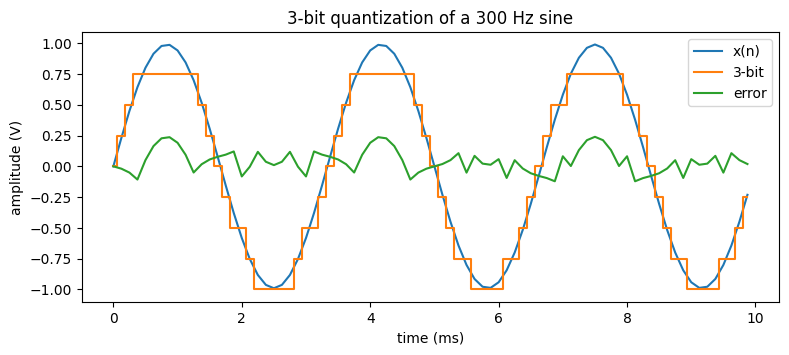

In [8]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.title("3-bit quantization of a 300 Hz sine")
plt.xlabel("time (ms)")
plt.ylabel("amplitude (V)")
plt.legend()
plt.show()

### Task 2.4 — Verify the 6 dB-per-bit rule (Lab 1A)
For B = 2, 4, 6, …, 16 bits, compute the measured SQNR = 10·log10(Σx² / Σe²) and compare it with the theoretical value 6.02·B + 1.76 dB.

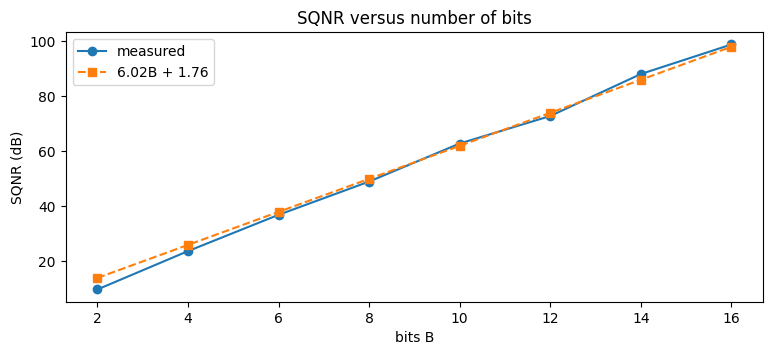

In [9]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.title("SQNR versus number of bits")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.show()

### Task 2.5 — Quantize your voice (Lab 1A)
Quantize my recording to 4, 8 and 12 bits, compute the SQNR of each version and listen to each.

In [10]:
fsv, xv = wavfile.read("my_voice.wav")
xv = xv.mean(axis=1) if xv.ndim > 1 else xv.astype(float)
xv = xv / np.max(np.abs(xv))

for B in [4, 8, 12]:
    xvq = quantize(xv, B)
    sqnr_v = 10*np.log10(np.sum(xv**2) / np.sum((xv - xvq)**2))
    print(f"B = {B:2d} bits | voice SQNR = {sqnr_v:5.1f} dB | full-scale sine theory = {6.02*B + 1.76:5.1f} dB")
    display(Audio(xvq, rate=fsv))

B =  4 bits | voice SQNR =  12.0 dB | full-scale sine theory =  25.8 dB


B =  8 bits | voice SQNR =  33.6 dB | full-scale sine theory =  49.9 dB


B = 12 bits | voice SQNR =  57.6 dB | full-scale sine theory =  74.0 dB


**Results for my voice (Task 2.5)**

| Bits B | Measured SQNR of my voice (dB) | Theory for a full-scale sine 6.02B + 1.76 (dB) | What I heard |
|---|---|---|---|
| 4 | 12.0 | 25.8 | more scratches (noisy) |
| 8 | 33.6 | 49.9 | fine |
| 12 | 57.6 | 74.0 | even cleaner |

**Listening observation (voice quantization).** At 4 bits the sound had more scratches (quantization noise). At 8 bits it sounded fine, and at 12 bits it sounded even cleaner. As the SQNR increases, the quantization noise becomes weaker compared with the voice, so the sound becomes better. The measured SQNR of my voice rises by about 6 dB for each extra bit, but it is lower than the theory value for a full-scale sine wave at every bit depth.

### Analysis questions (Lab 1A)
**Q1.** Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when fs = 10 Hz.

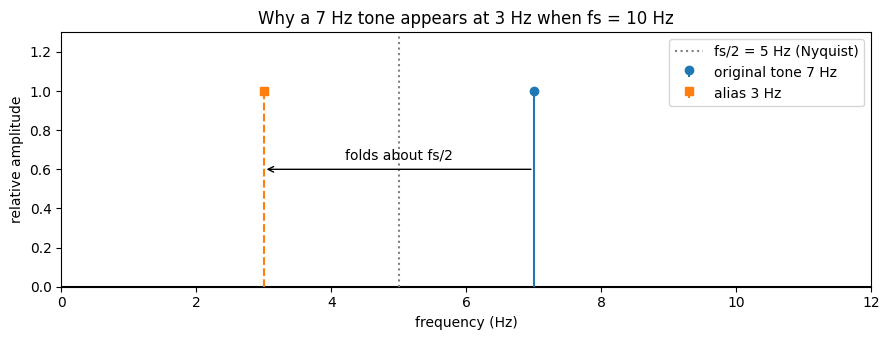

In [11]:
fs_s, F = 10, 7
F_alias = abs(F - fs_s*round(F/fs_s))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axhline(0, color="k")
ax.stem([F], [1], linefmt="C0-", markerfmt="C0o", basefmt=" ", label=f"original tone {F} Hz")
ax.stem([F_alias], [1], linefmt="C1--", markerfmt="C1s", basefmt=" ", label=f"alias {F_alias} Hz")
ax.axvline(fs_s/2, color="gray", linestyle=":", label=f"fs/2 = {fs_s/2:g} Hz (Nyquist)")
ax.annotate("", xy=(F_alias, 0.6), xytext=(F, 0.6), arrowprops=dict(arrowstyle="->"))
ax.text((F + F_alias)/2, 0.65, "folds about fs/2", ha="center")
ax.set_xlim(0, 12)
ax.set_ylim(0, 1.3)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("relative amplitude")
ax.set_title("Why a 7 Hz tone appears at 3 Hz when fs = 10 Hz")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Answer 1.** Sampling at fs = 10 Hz can only represent frequencies from 0 up to fs/2 = 5 Hz. The 7 Hz tone is above this limit, so after sampling it folds back about fs/2 = 5 Hz and appears at 10 − 7 = 3 Hz. This is the formula F_alias = |F − k·fs| = |7 − 1 × 10| = 3 Hz. The samples of the 7 Hz cosine are exactly the same numbers as the samples of a 3 Hz cosine (the black dots in Task 2.1 lie on both curves), so after sampling nobody can tell which tone was there. The frequency-axis sketch above shows the 7 Hz tone, the fs/2 line and the 3 Hz alias.

**Q2.** In Task 2.2, why can the aliasing heard in the naive version not be removed afterwards?

**Answer 2.** When samples are taken without a filter, the alias is stored in the samples as a perfectly normal low-frequency tone. The samples of the original high-frequency tone are exactly the same numbers as the samples of a lower-frequency tone (in Task 2.1 the samples of the 7 Hz and the 3 Hz tones were identical). So nothing in the samples shows which part is real and which is an alias, and a filter cannot separate them. Aliasing must be prevented before downsampling, by low-pass filtering first, which is what signal.decimate does. In the sweep test the naive version kept a false tone until the end, while the proper version removed the frequencies above the limit before they could fold back.

**Q3.** By how much does the SQNR change when one bit is added? Does your measurement agree?


In [12]:
per_bit = np.diff(meas) / np.diff(bits)
print("Change in SQNR per extra bit (dB):", np.round(per_bit, 2))
print(f"Average change per bit = {np.mean(per_bit):.2f} dB (theory: 6.02 dB)")


Change in SQNR per extra bit (dB): [6.99 6.62 6.06 6.94 5.01 7.65 5.39]
Average change per bit = 6.38 dB (theory: 6.02 dB)


**Answer 3.** Each extra bit adds about 6 dB to the SQNR (theory: 6.02 dB per bit). An extra bit doubles the number of quantization levels, so the step Δ is halved and the noise power becomes four times smaller, and a factor of 4 is 6.02 dB. My measurement agrees: in Task 2.4 the SQNR rose by an average of about 6.4 dB per bit (single steps between about 5 and 7.6 dB), and the measured line follows the theory line 6.02B + 1.76. The small differences come from using only 80 samples and from clipping at the signal peaks at low bit depths.

In [13]:
# Lab 1A - Task 2.5 (question): why is speech SQNR lower than a sine's?
t_s = np.arange(0, 0.01, 1/8000)
sine_test = 0.99 * np.sin(2*np.pi*300*t_s)          # the full-scale sine from Task 2.3

rms_voice = np.sqrt(np.mean(xv**2))                  # RMS = average strength of the signal
rms_sine  = np.sqrt(np.mean(sine_test**2))

print(f"RMS voice = {rms_voice:.3f}   RMS sine = {rms_sine:.3f}")
print(f"Voice is {20*np.log10(rms_sine/rms_voice):.1f} dB weaker than the sine")
print(f"Crest factor (peak / RMS): voice = {np.max(np.abs(xv))/rms_voice:.1f}, sine = {np.max(np.abs(sine_test))/rms_sine:.2f}")

RMS voice = 0.107   RMS sine = 0.700
Voice is 16.3 dB weaker than the sine
Crest factor (peak / RMS): voice = 9.3, sine = 1.41


**Task 2.5 question.** Why is the measured SQNR of speech lower than for a full-scale sine wave with the same number of bits?

**Answer.** The quantization noise power depends only on the step size Δ (it is Δ²/12), so it is the same for speech and for a sine at the same number of bits. SQNR is signal power divided by this noise power. A full-scale sine uses the whole range all the time (RMS about 0.70), but speech is mostly quiet and only occasionally reaches the peaks (RMS about 0.107, which is about 16 dB weaker). Weaker signal power over the same noise power gives a lower SQNR, and my measurements show this gap of about 16 dB at 8 and 12 bits (33.6 dB vs 49.9 dB, and 57.6 dB vs 74.0 dB). Speech also has a high crest factor (peak much larger than RMS), so most of its samples use only a few of the available levels. The 6.02B + 1.76 formula assumes a full-scale sine, so for speech the SQNR is lower by the amount the signal sits below full scale.

In [14]:
# Lab 1A - Analysis Q4: temperature sensor, choosing bits and sampling rate
span, resolution = 100.0, 0.01            # range 0-100 degC, required resolution 0.01 degC
levels = span / resolution                 # how many different values we must tell apart
bits_needed = int(np.ceil(np.log2(levels)))

print(f"Levels needed = {levels:.0f}")
print(f"log2(levels) = {np.log2(levels):.2f}  ->  bits needed = {bits_needed}")
print(f"13 bits: {2**13} levels, step = {span/2**13:.5f} degC  (too coarse)")
print(f"{bits_needed} bits: {2**bits_needed} levels, step = {span/2**bits_needed:.5f} degC  (meets 0.01)")

max_rate, fs_choice = 0.1, 1.0             # degC per second, samples per second
print(f"At fs = {fs_choice:.0f} Hz the temperature moves at most {max_rate/fs_choice:.2f} degC between samples")

Levels needed = 10000
log2(levels) = 13.29  ->  bits needed = 14
13 bits: 8192 levels, step = 0.01221 degC  (too coarse)
14 bits: 16384 levels, step = 0.00610 degC  (meets 0.01)
At fs = 1 Hz the temperature moves at most 0.10 degC between samples


**Q4.** A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.

**Answer 4.** *Number of bits:* a resolution of 0.01 °C over 0–100 °C needs 100 / 0.01 = 10,000 levels. Since B bits give 2^B levels, 13 bits (8,192 levels, step 0.0122 °C) are not enough, while 14 bits (16,384 levels, step 0.0061 °C) meet the requirement. So I suggest **14 bits**. *Sampling rate:* the temperature changes by at most 0.1 °C per second, so it is a very slow signal with almost no high-frequency content, and the Nyquist condition fs > 2F is met by a very large margin even at a low rate. I suggest **1 sample per second (1 Hz)**: between two samples the temperature moves by at most 0.1 °C, so no change is missed, and a higher rate would only waste power and storage. The 1 Hz rate also leaves room to average several readings to reduce noise, and a simple analog low-pass filter before the converter is still needed so that fast interference (for example 50 Hz mains hum) does not alias into the slow signal.

## AI-use statement

- **Tool:** Claude (Anthropic).
- **Used for:** step-by-step guidance on setting up and running this lab in Google Colab, the code for Tasks 2.1–2.5, explanations of what each part of the code does, and first drafts of the pre-lab answer, the written observations after the tasks, and the answers to the analysis questions and the Task 2.5 question. The listening observations in Tasks 2.2 and 2.5 are what I heard through the audio players; Claude helped to word them in the notebook.
- **How I verified it:** I ran every cell myself and checked the results against the theory (alias frequency |F − k·fs|, SQNR ≈ 6.02B + 1.76 dB, about 6 dB per extra bit). I listened to the audio results myself.